# 06 · Evaluation, calibration and decision threshold

The final model is chosen: the default HistGradientBoosting on the cleaned data plus `weighted_past_due` (notebooks 03–05). Kaggle scores it with ROC-AUC only, but a lender needs two more things before using it:

1. **Trustworthy probabilities (calibration):** of the applicants who get 20%, do about 20% really default?
2. **A decision rule (threshold):** from which probability is an application rejected?

Everything here uses **out-of-fold predictions**: each training row is predicted by the fold model that did not train on it, with the same 5 folds as notebooks 03–05. That gives one honest prediction for each of the 149,391 rows, without touching the Kaggle test set.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from credit_risk_ai.data.prepare import prepare_train
from credit_risk_ai.models.pipeline import RANDOM_STATE, build_hist_gradient_boosting

N_SPLITS = 5

# Chart colours (same as notebooks 02-03): model in blue, chosen point in orange
BLUE, ORANGE = "#2a78d6", "#eb6834"
GRAY, INK, GRID = "#898781", "#52514e", "#e1e0d9"

## Step 1 · Out-of-fold predictions

`cross_val_predict` trains 5 models (one per fold) and puts together their predictions on the rows each one did **not** train on. Checks: one prediction per row, and the average prediction should be close to the real default rate (6.7%).

In [2]:
X, y = prepare_train()
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Column 1 of predict_proba = probability of default
oof = cross_val_predict(
    build_hist_gradient_boosting(), X, y, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
is_default = y.to_numpy() == 1

print(f"predictions: {len(oof):,} (rows in X: {len(X):,})")
print(f"mean predicted probability: {oof.mean():.4f}")
print(f"actual default rate:        {is_default.mean():.4f}")

predictions: 149,391 (rows in X: 149,391)
mean predicted probability: 0.0670
actual default rate:        0.0670


## Step 2 · Overall evaluation (threshold-free metrics)

The final model against a "model" that knows nothing and gives everyone the default rate (6.7%).

ROC-AUC here is computed once on all 149,391 out-of-fold predictions, so it can differ from the mean of the 5 per-fold scores (0.8651) in the 4th decimal.

In [3]:
base_rate = is_default.mean()

evaluation = pd.DataFrame({
    "final model": {
        "ROC-AUC": roc_auc_score(y, oof),
        "PR-AUC": average_precision_score(y, oof),
        "Brier score": brier_score_loss(y, oof),
    },
    "everyone gets the base rate": {
        "ROC-AUC": 0.5,                              # no ranking at all
        "PR-AUC": base_rate,                         # precision of a random ranking
        "Brier score": base_rate * (1 - base_rate),  # p x (1 - p)
    },
})
evaluation["better when"] = ["higher", "higher", "lower"]
evaluation.round(4)

,final model,everyone gets the base rate,better when
ROC-AUC,0.8650,0.5000,higher
PR-AUC,0.3958,0.0670,higher
Brier score,0.0492,0.0625,lower


## Step 3 · Calibration

Sort the rows by predicted probability, cut them into 10 groups of equal size (about 14,900 rows each), and compare each group's **mean predicted probability** with its **observed default rate**. A perfectly calibrated model sits on the diagonal. Both axes are on a log scale because most predictions are below 5%.

**Decision rule (fixed before looking):** apply isotonic calibration only if it lowers the Brier score by at least 0.0005 (about 1%).

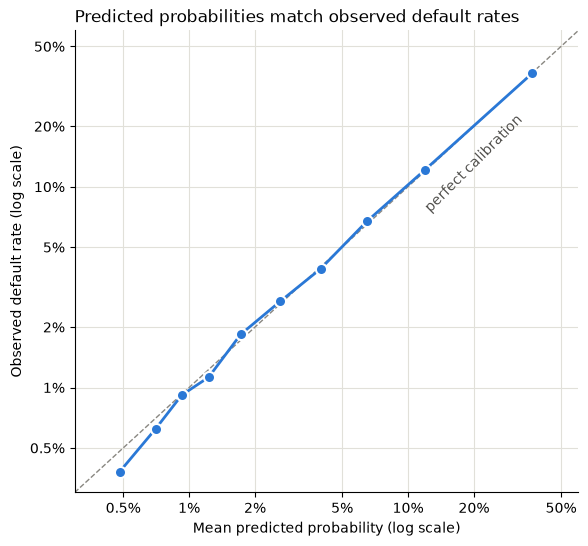

,mean predicted,observed default rate
group (low -> high risk),,
0,0.0048,0.0038
1,0.0070,0.0062
2,0.0093,0.0092
3,0.0123,0.0112
4,0.0172,0.0184
5,0.0261,0.0268
6,0.0399,0.0390
7,0.0648,0.0671
8,0.1198,0.1216


In [4]:
observed, predicted = calibration_curve(y, oof, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6.5, 6))
limits = [0.003, 0.6]
ax.plot(limits, limits, color=GRAY, linestyle="--", linewidth=1)
ax.text(0.2, 0.13, "perfect calibration", color=INK, rotation=45, ha="center", va="center")
ax.plot(predicted, observed, color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=1.5)

ticks = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
labels = ["0.5%", "1%", "2%", "5%", "10%", "20%", "50%"]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(ticks, labels)
ax.set_yticks(ticks, labels)
ax.minorticks_off()
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel("Mean predicted probability (log scale)")
ax.set_ylabel("Observed default rate (log scale)")
ax.set_title("Predicted probabilities match observed default rates", loc="left")
ax.grid(color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

calibration = pd.DataFrame({"mean predicted": predicted, "observed default rate": observed})
calibration.index.name = "group (low -> high risk)"
calibration.round(4)

Can a separate calibration step still help? `CalibratedClassifierCV` with isotonic regression is fitted **inside** each outer fold (with its own inner 3-fold split), so its out-of-fold predictions are as honest as the raw ones.

In [5]:
MIN_BRIER_GAIN = 0.0005   # decision rule above

calibrated = CalibratedClassifierCV(build_hist_gradient_boosting(), method="isotonic", cv=3)
oof_calibrated = cross_val_predict(calibrated, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

brier_raw = brier_score_loss(y, oof)
brier_calibrated = brier_score_loss(y, oof_calibrated)
gain = brier_raw - brier_calibrated

print(f"Brier, raw model:           {brier_raw:.5f}")
print(f"Brier, isotonic-calibrated: {brier_calibrated:.5f}   (gain {gain:+.5f})")
print("Decision:", "calibrate" if gain >= MIN_BRIER_GAIN else "keep the raw probabilities")

Brier, raw model:           0.04920
Brier, isotonic-calibrated: 0.04909   (gain +0.00011)
Decision: keep the raw probabilities


## Step 4 · Decision threshold from the cost of errors

Rejecting an application can go wrong in two ways:

| Error | What happens | Cost |
|---|---|---|
| **False negative** (missed defaulter) | Loan approved, borrower defaults | Part of the loan is lost |
| **False positive** (wrongly rejected) | Good borrower turned away | The interest we would have earned is lost |

**Assumption (to be confirmed by the business):** a missed defaulter costs **5 times** as much as a wrongly rejected good borrower. For example, a default loses about half of the loan, while a rejected good borrower costs about 10% of it in lost interest.

**Theory:** for an applicant with probability of default *p*, rejecting costs (1 − *p*) × cost_FP and approving costs *p* × cost_FN. Rejecting is cheaper when *p* > cost_FP / (cost_FP + cost_FN) = 1 / (1 + 5) ≈ **0.167**. This only works if the probabilities are well calibrated, which step 3 showed.

Check the theory on the data: the total cost of every threshold from 0.01 to 0.6.

In [6]:
COST_FN = 5   # missed defaulter (assumption, see above)
COST_FP = 1   # good borrower wrongly rejected


def total_cost(threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    """Total cost on the out-of-fold predictions when rejecting every p >= threshold."""
    reject = oof >= threshold
    false_negatives = (~reject & is_default).sum()
    false_positives = (reject & ~is_default).sum()
    return cost_fn * false_negatives + cost_fp * false_positives


thresholds = np.round(np.arange(0.01, 0.60, 0.005), 3)
costs = np.array([total_cost(t) for t in thresholds])

best_threshold = thresholds[costs.argmin()]
theory_threshold = COST_FP / (COST_FP + COST_FN)
print(f"lowest-cost threshold on the data: {best_threshold:.3f}")
print(f"threshold from theory, 1 / (1 + 5): {theory_threshold:.3f}")

lowest-cost threshold on the data: 0.160
threshold from theory, 1 / (1 + 5): 0.167


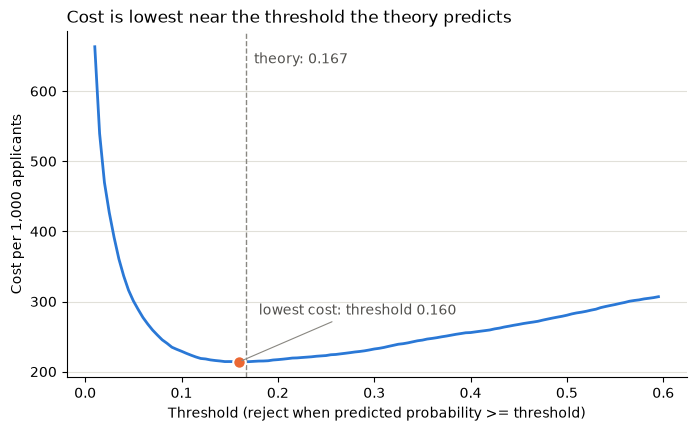

In [7]:
cost_per_1000 = costs / len(y) * 1000   # in units of one wrongly rejected good borrower

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, cost_per_1000, color=BLUE, linewidth=2)
ax.axvline(theory_threshold, color=GRAY, linestyle="--", linewidth=1)
ax.annotate(f"theory: {theory_threshold:.3f}", xy=(theory_threshold, cost_per_1000.max()),
            xytext=(6, -4), textcoords="offset points", va="top", color=INK)
best_cost = cost_per_1000.min()
ax.plot(best_threshold, best_cost, "o", color=ORANGE, markersize=9,
        markeredgecolor="white", markeredgewidth=1.5)
ax.annotate(f"lowest cost: threshold {best_threshold:.3f}", xy=(best_threshold, best_cost),
            xytext=(14, 34), textcoords="offset points", color=INK,
            arrowprops={"arrowstyle": "-", "color": GRAY, "linewidth": 0.8})

ax.set_xlabel("Threshold (reject when predicted probability >= threshold)")
ax.set_ylabel("Cost per 1,000 applicants")
ax.set_title("Cost is lowest near the threshold the theory predicts", loc="left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

How much does the threshold depend on the cost assumption? The same check for other cost ratios:

In [8]:
sensitivity = []
for ratio in [2, 5, 10]:
    ratio_costs = np.array([total_cost(t, cost_fn=ratio, cost_fp=1) for t in thresholds])
    best = thresholds[ratio_costs.argmin()]
    sensitivity.append({
        "missed defaulter costs x times more": ratio,
        "theory threshold": 1 / (1 + ratio),
        "lowest-cost threshold on data": best,
        "share of applicants rejected": (oof >= best).mean(),
    })

pd.DataFrame(sensitivity).round(3)

,missed defaulter costs x times more,theory threshold,lowest-cost threshold on data,share of applicants rejected
0,2,0.333,0.335,0.048
1,5,0.167,0.160,0.112
2,10,0.091,0.090,0.186


**Choice:** use the theory threshold, 1 / (1 + 5) ≈ 0.167. The lowest-cost threshold on the data is picked on these same rows (slightly optimistic, like the best of 30 in notebook 05) and moves a little with noise; the theory threshold follows directly from the calibrated probabilities and the cost assumption, and the two agree for every cost ratio.

## Step 5 · What the threshold means in practice

The chosen threshold next to other common choices:

- **0.5:** what `predict()` uses silently (the trap from notebook 02).
- **Max F1:** treats both errors as equally costly.
- **Capacity:** if the credit team can only review the riskiest 10% of applications.

In [9]:
DECISION_THRESHOLD = theory_threshold


def threshold_report(threshold):
    reject = oof >= threshold
    tn, fp, fn, tp = confusion_matrix(is_default, reject).ravel()
    return {
        "threshold": threshold,
        "share rejected": reject.mean(),
        "precision": tp / (tp + fp),   # of the rejected, share who would have defaulted
        "recall": tp / (tp + fn),      # of the defaulters, share caught
        "F1": f1_score(is_default, reject),
        "cost per 1,000 applicants": (COST_FN * fn + COST_FP * fp) / len(y) * 1000,
    }


max_f1_threshold = thresholds[np.argmax([f1_score(is_default, oof >= t) for t in thresholds])]
candidates = {
    "predict() default": 0.5,
    "max F1": max_f1_threshold,
    "capacity: riskiest 10%": np.quantile(oof, 0.90),
    "cost-based (chosen)": DECISION_THRESHOLD,
}
pd.DataFrame({name: threshold_report(t) for name, t in candidates.items()}).T.round(3)

,threshold,share rejected,precision,recall,F1,"cost per 1,000 applicants"
predict() default,0.500,0.021,0.598,0.188,0.286,280.445
max F1,0.190,0.095,0.376,0.534,0.441,215.528
capacity: riskiest 10%,0.180,0.100,0.366,0.547,0.439,215.107
cost-based (chosen),0.167,0.108,0.353,0.570,0.436,214.250


In [10]:
reject = oof >= DECISION_THRESHOLD
tn, fp, fn, tp = confusion_matrix(is_default, reject).ravel()
per_10k = 10_000 / len(y)

print(f"Out of 10,000 applicants, rejecting when p >= {DECISION_THRESHOLD:.3f}:")
print(f"  rejected, would have defaulted (caught):        {tp * per_10k:6.0f}")
print(f"  rejected, would have repaid (lost business):    {fp * per_10k:6.0f}")
print(f"  approved, then defaulted (missed):              {fn * per_10k:6.0f}")
print(f"  approved, repaid:                               {tn * per_10k:6.0f}")

Out of 10,000 applicants, rejecting when p >= 0.167:
  rejected, would have defaulted (caught):           382
  rejected, would have repaid (lost business):       701
  approved, then defaulted (missed):                 288
  approved, repaid:                                 8629


## Step 6 · Conclusions

**Evaluation of the final model** (out-of-fold, 149,391 rows): ROC-AUC **0.865**, PR-AUC **0.396** (vs 0.067 for no model), Brier score **0.0492** (21% lower than giving everyone the base rate, 0.0625).

**Findings**

1. **The probabilities can be trusted as they are.** In all 10 risk groups the mean prediction is close to the observed default rate, and the average prediction (6.70%) equals the real rate. Isotonic calibration lowers the Brier score by only about 0.0001, far below the 0.0005 bar, so no calibration step is added. (HistGradientBoosting minimises log loss, which tends to give well-calibrated probabilities.)
2. **Because the probabilities are calibrated, the best threshold follows from the costs alone:** 1 / (1 + cost ratio). On the data, the lowest-cost threshold matches the theory for cost ratios 2, 5 and 10.
3. **The default threshold of 0.5 is far from optimal.** It rejects only 2% of applicants and catches 19% of defaulters, and costs about 31% more than the cost-based threshold (280 vs 214 per 1,000 applicants). The cost-based threshold (0.167) rejects about 11% and catches about 57% of defaulters. Near the minimum the cost curve is flat: max F1 (0.19) and the 10% capacity rule (0.18) cost less than 1% more, so the exact value matters much less than avoiding 0.5.
4. **The threshold is a business decision.** It depends entirely on the cost ratio: 2 → about 0.33 (5% rejected), 5 → 0.167 (11%), 10 → about 0.09 (19%).

**Decision:** keep the raw probabilities; reject when the probability of default is at least **1 / (1 + 5) ≈ 0.167**, under the assumption that a missed defaulter costs 5 times a wrongly rejected good borrower.

**Not covered here:** the score on new data (submit `submissions/submission.csv` to Kaggle), and whether the 5:1 cost ratio is right for a real lender.

**Next step:** store the cost ratio and threshold in `src`, and let the API return a decision (approve / reject) next to the probability.